# Higher Return On First Day Indicates Higher Return In 1 Year? Benchmark: NIFTY50 Prices

## Data and Libraries Import

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


import warnings
warnings.filterwarnings('ignore')

import os
from dotenv import load_dotenv
from pathlib import Path

from sqlalchemy import create_engine, text

In [2]:
env_path = Path.cwd()/"github_repo_cloned"/"ipo_reality_check"/".env"
load_dotenv(env_path)


host = os.getenv("DB_HOST")
user = os.getenv("DB_USER")
port = os.getenv("DB_PORT")
password = os.getenv("DB_PASSword")
db = os.getenv("DB_NAME")


In [3]:
engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{db}")

def sql(query, engine = engine):
    with engine.connect() as conn:
        df = pd.read_sql(text(query),conn)
    return df

In [4]:
data = sql('select * from overall_growth')

In [5]:
data.head()

,company,listing_date,date_after_a_year,first_day_price,last_day_price,growth_first_day,nifty_open,nifty_close,nifty_growth,ipo_growth,excess_return
0,ACME Solar Holdings Ltd.,2024-11-13,2025-11-13,251.0,251.05,0.86,23822.45,25879.15,8.63,0.02,-8.61
1,AGS Transact Technologies Ltd.,2022-01-31,2023-01-31,175.0,58.05,-7.97,17301.05,17662.15,2.09,-66.83,-68.92
2,ASK Automotive Ltd.,2023-11-15,2024-11-18,303.3,436.90,2.24,19651.40,23453.80,19.35,44.05,24.70
3,Aadhar Housing Finance Ltd.,2024-05-15,2025-05-15,315.0,447.05,4.59,22255.60,25062.10,12.61,41.92,29.31
4,Abans Holdings Ltd.,2022-12-23,2023-12-26,273.0,317.30,-20.00,17977.65,21441.35,19.27,16.23,-3.04


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   company            302 non-null    object 
 1   listing_date       302 non-null    object 
 2   date_after_a_year  302 non-null    object 
 3   first_day_price    302 non-null    float64
 4   last_day_price     302 non-null    float64
 5   growth_first_day   295 non-null    float64
 6   nifty_open         302 non-null    float64
 7   nifty_close        301 non-null    float64
 8   nifty_growth       301 non-null    float64
 9   ipo_growth         302 non-null    float64
 10  excess_return      301 non-null    float64
dtypes: float64(8), object(3)
memory usage: 26.1+ KB


In [7]:
pd.set_option('display.max_columns',None)

## Initial Data Checking

Fixing the date column to convert them into date format

In [8]:
data['listing_date']=pd.to_datetime(data['listing_date'])

In [9]:
data['date_after_a_year']=pd.to_datetime(data['date_after_a_year'])

Renaming the column names

In [10]:
rename_dict = {
    'listing_date':'open_date',
    'date_after_a_year':'close_date',
    'first_day_price':'open_price',
    'last_day_price':'close_price',
    'growth_first_day':'init_growth',
    'nifty_open':'nifty_open',
    'nifty_close':'nifty_close',
    'nifty_growth':'nifty_growth',
}


data.rename(columns=rename_dict,inplace=True)

data.head()

,company,open_date,close_date,open_price,close_price,init_growth,nifty_open,nifty_close,nifty_growth,ipo_growth,excess_return
0,ACME Solar Holdings Ltd.,2024-11-13,2025-11-13,251.0,251.05,0.86,23822.45,25879.15,8.63,0.02,-8.61
1,AGS Transact Technologies Ltd.,2022-01-31,2023-01-31,175.0,58.05,-7.97,17301.05,17662.15,2.09,-66.83,-68.92
2,ASK Automotive Ltd.,2023-11-15,2024-11-18,303.3,436.90,2.24,19651.40,23453.80,19.35,44.05,24.70
3,Aadhar Housing Finance Ltd.,2024-05-15,2025-05-15,315.0,447.05,4.59,22255.60,25062.10,12.61,41.92,29.31
4,Abans Holdings Ltd.,2022-12-23,2023-12-26,273.0,317.30,-20.00,17977.65,21441.35,19.27,16.23,-3.04


Null Value Checking

In [11]:
data.isnull().sum().reset_index(name = 'null_values')

,index,null_values
0,company,0
1,open_date,0
2,close_date,0
3,open_price,0
4,close_price,0
5,init_growth,7
6,nifty_open,0
7,nifty_close,1
8,nifty_growth,1
9,ipo_growth,0


Removing null values

In [12]:
removed_companies = data[data.isna().any(axis=1)]['company'].tolist()

In [13]:
data = data.dropna()

In [14]:
data[data['company'].duplicated()]

,company,open_date,close_date,open_price,close_price,init_growth,nifty_open,nifty_close,nifty_growth,ipo_growth,excess_return


Adding beat_nifty column

In [15]:
data['beat_nifty']=data['excess_return'].apply(lambda x: 'yes' if x>= 0 else 'no')

In [16]:
data.head()

,company,open_date,close_date,open_price,close_price,init_growth,nifty_open,nifty_close,nifty_growth,ipo_growth,excess_return,beat_nifty
0,ACME Solar Holdings Ltd.,2024-11-13,2025-11-13,251.0,251.05,0.86,23822.45,25879.15,8.63,0.02,-8.61,no
1,AGS Transact Technologies Ltd.,2022-01-31,2023-01-31,175.0,58.05,-7.97,17301.05,17662.15,2.09,-66.83,-68.92,no
2,ASK Automotive Ltd.,2023-11-15,2024-11-18,303.3,436.90,2.24,19651.40,23453.80,19.35,44.05,24.70,yes
3,Aadhar Housing Finance Ltd.,2024-05-15,2025-05-15,315.0,447.05,4.59,22255.60,25062.10,12.61,41.92,29.31,yes
4,Abans Holdings Ltd.,2022-12-23,2023-12-26,273.0,317.30,-20.00,17977.65,21441.35,19.27,16.23,-3.04,no


Plotting the growth data to see which is the threshold for high and low growth

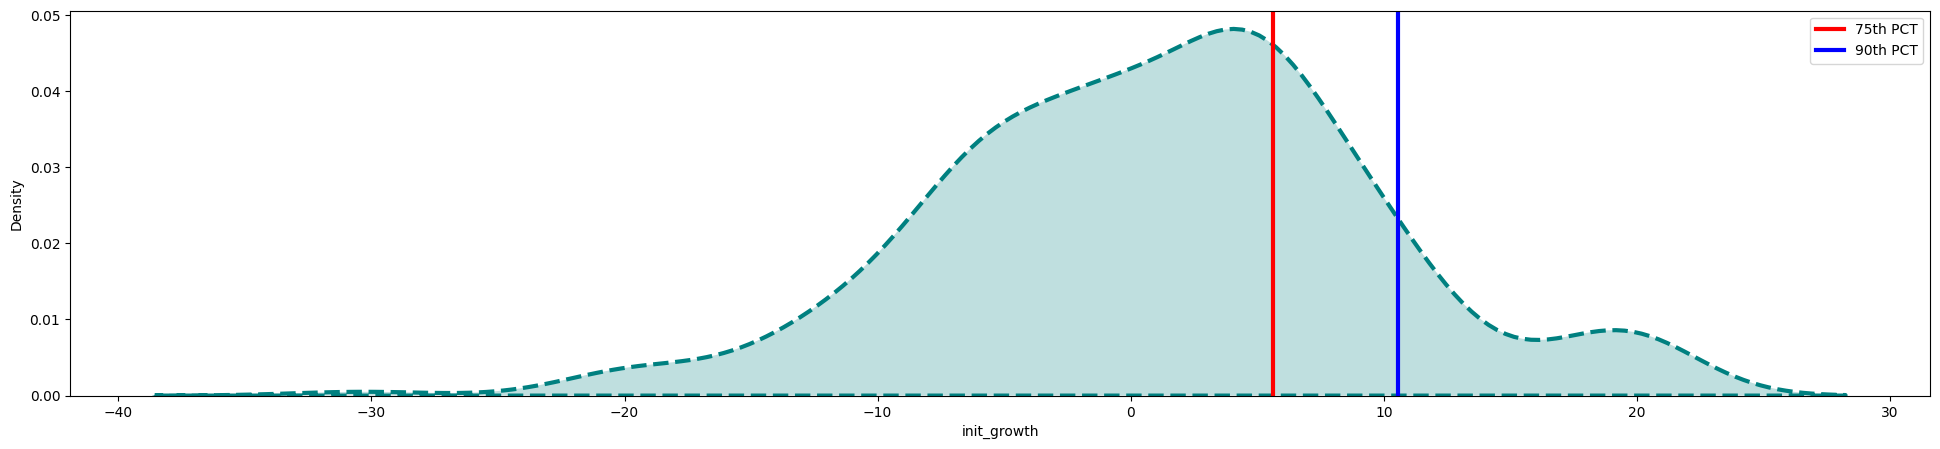

In [ ]:
plt.figure(figsize=(24,5))
sns.kdeplot(x = 'init_growth',data=data,linewidth = 3,color = 'teal',linestyle = "--",fill =True)
plt.axvline(data['init_growth'].quantile(0.75),label = '75th PCT',color = 'Red',linewidth = 3)
plt.axvline(data['init_growth'].quantile(0.90),label = '90th PCT',color = 'Blue',linewidth = 3)
plt.legend()
plt.show()

Adding labeled column to my data correspond to growth

In [22]:
data['growth'] =data['init_growth'].apply(lambda x: 'high' if x>= data['init_growth'].quantile(.75) else 'low')

In [23]:
data.head()

,company,open_date,close_date,open_price,close_price,init_growth,nifty_open,nifty_close,nifty_growth,ipo_growth,excess_return,beat_nifty,growth
0,ACME Solar Holdings Ltd.,2024-11-13,2025-11-13,251.0,251.05,0.86,23822.45,25879.15,8.63,0.02,-8.61,no,low
1,AGS Transact Technologies Ltd.,2022-01-31,2023-01-31,175.0,58.05,-7.97,17301.05,17662.15,2.09,-66.83,-68.92,no,low
2,ASK Automotive Ltd.,2023-11-15,2024-11-18,303.3,436.90,2.24,19651.40,23453.80,19.35,44.05,24.70,yes,low
3,Aadhar Housing Finance Ltd.,2024-05-15,2025-05-15,315.0,447.05,4.59,22255.60,25062.10,12.61,41.92,29.31,yes,low
4,Abans Holdings Ltd.,2022-12-23,2023-12-26,273.0,317.30,-20.00,17977.65,21441.35,19.27,16.23,-3.04,no,low


## Analyais and Results

Statistics in both the high and low valued IPO's

In [25]:
summary_df = data.groupby('growth').agg(
    ipo_count = ('company','count'),
    ipo_return_mean = ('ipo_growth','mean'),
    ipo_return_median = ('ipo_growth','median'),
    nift_return_mean = ('nifty_growth','mean'),
    nift_return_median = ('nifty_growth','median'),
    excess_return_mean = ('excess_return','mean'),
    excess_return_median = ('excess_return','median'),
    beat_pct = ('beat_nifty',lambda x: (x == 'yes').mean() * 100)
).round(2).reset_index()

summary_df

,growth,ipo_count,ipo_return_mean,ipo_return_median,nift_return_mean,nift_return_median,excess_return_mean,excess_return_median,beat_pct
0,high,74,24.61,-5.44,11.13,8.23,13.48,-12.48,40.54
1,low,220,17.88,0.44,10.41,8.38,7.47,-7.11,43.64


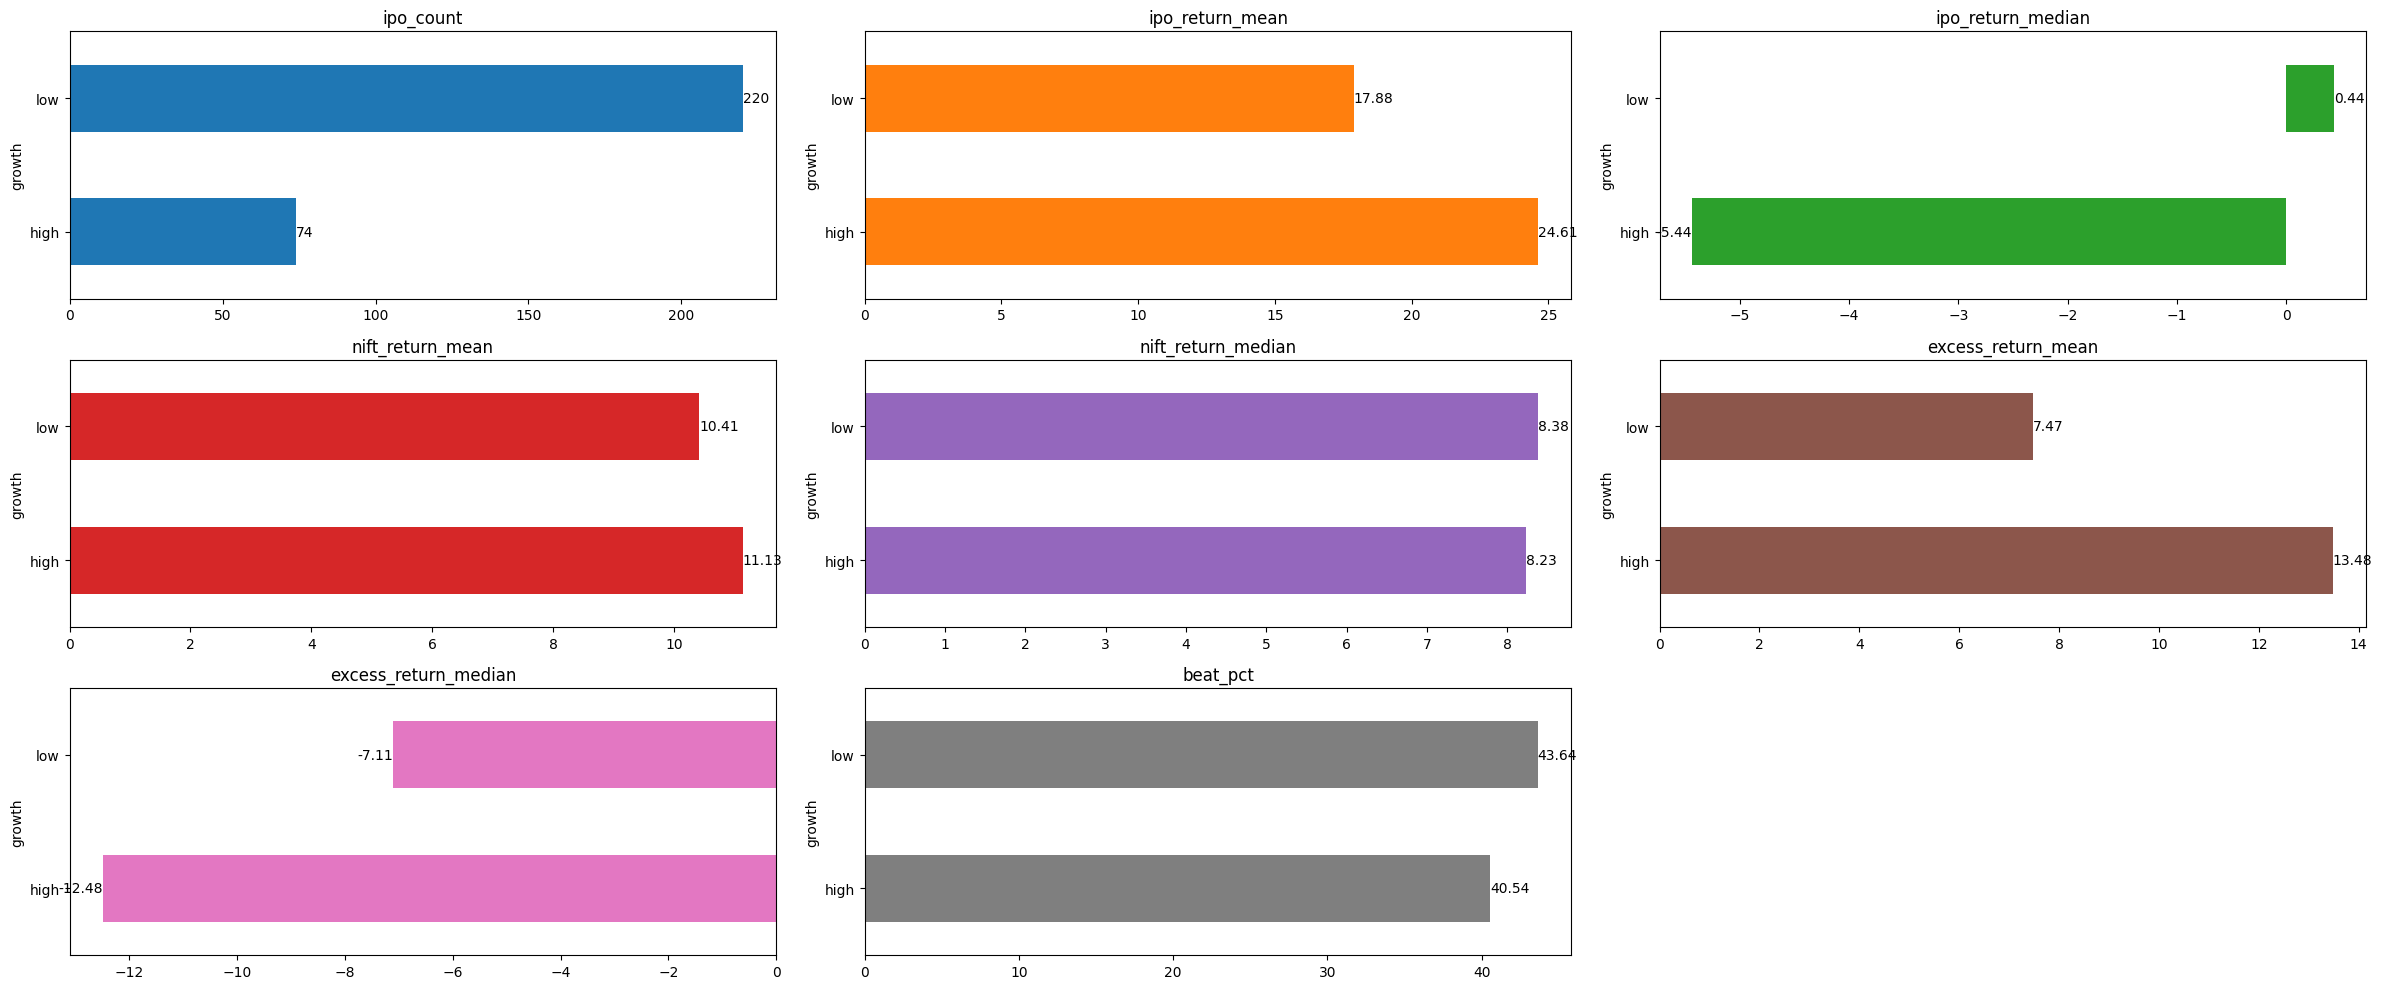

In [46]:
axes = summary_df.set_index('growth').plot(kind = 'barh',\
                                           subplots=True,\
                                            layout=(3,3),\
                                                figsize=(24,10),\
                                                    sharex=False,\
                                                        legend = False)
for ax in axes.flatten():
    for container in ax.containers:
        ax.bar_label(container)
plt.tight_layout()
plt.show()

Statistics gropued by year, to see any particular difference

In [48]:
summary_by_year = data.groupby(['growth',data['open_date'].dt.year]).agg(
    ipo_count = ('company','count'),
    ipo_return_mean = ('ipo_growth','mean'),
    ipo_return_median = ('ipo_growth','median'),
    nifty_return_mean = ('nifty_growth','mean'),
    nifty_return_median = ('nifty_growth','median'),
    excess_return_mean = ('excess_return','mean'),
    excess_return_median = ('excess_return','median'),
    beat_pct = ('beat_nifty',lambda x: (x == 'yes').mean() * 100)
).round(2).reset_index()

summary_by_year

,growth,open_date,ipo_count,ipo_return_mean,ipo_return_median,nifty_return_mean,nifty_return_median,excess_return_mean,excess_return_median,beat_pct
0,high,2019,3,57.65,77.63,2.20,5.60,55.45,87.40,66.67
1,high,2020,5,106.62,85.99,36.55,35.92,70.07,43.59,80.00
2,high,2021,18,16.99,-12.21,8.43,6.50,8.56,-16.64,38.89
3,high,2022,7,26.37,0.00,9.98,10.93,16.39,-6.41,42.86
4,high,2023,13,53.95,26.11,24.08,25.91,29.88,0.02,53.85
5,high,2024,22,1.85,-12.79,4.56,5.64,-2.72,-18.00,27.27
6,high,2025,6,-19.57,-16.02,-0.09,-4.81,-19.47,-22.30,16.67
7,low,2019,12,24.58,15.50,-2.55,2.82,27.13,26.67,75.00
8,low,2020,7,128.71,101.77,53.49,53.68,75.22,48.84,57.14
9,low,2021,43,-5.76,-18.03,7.47,6.62,-13.23,-24.38,27.91


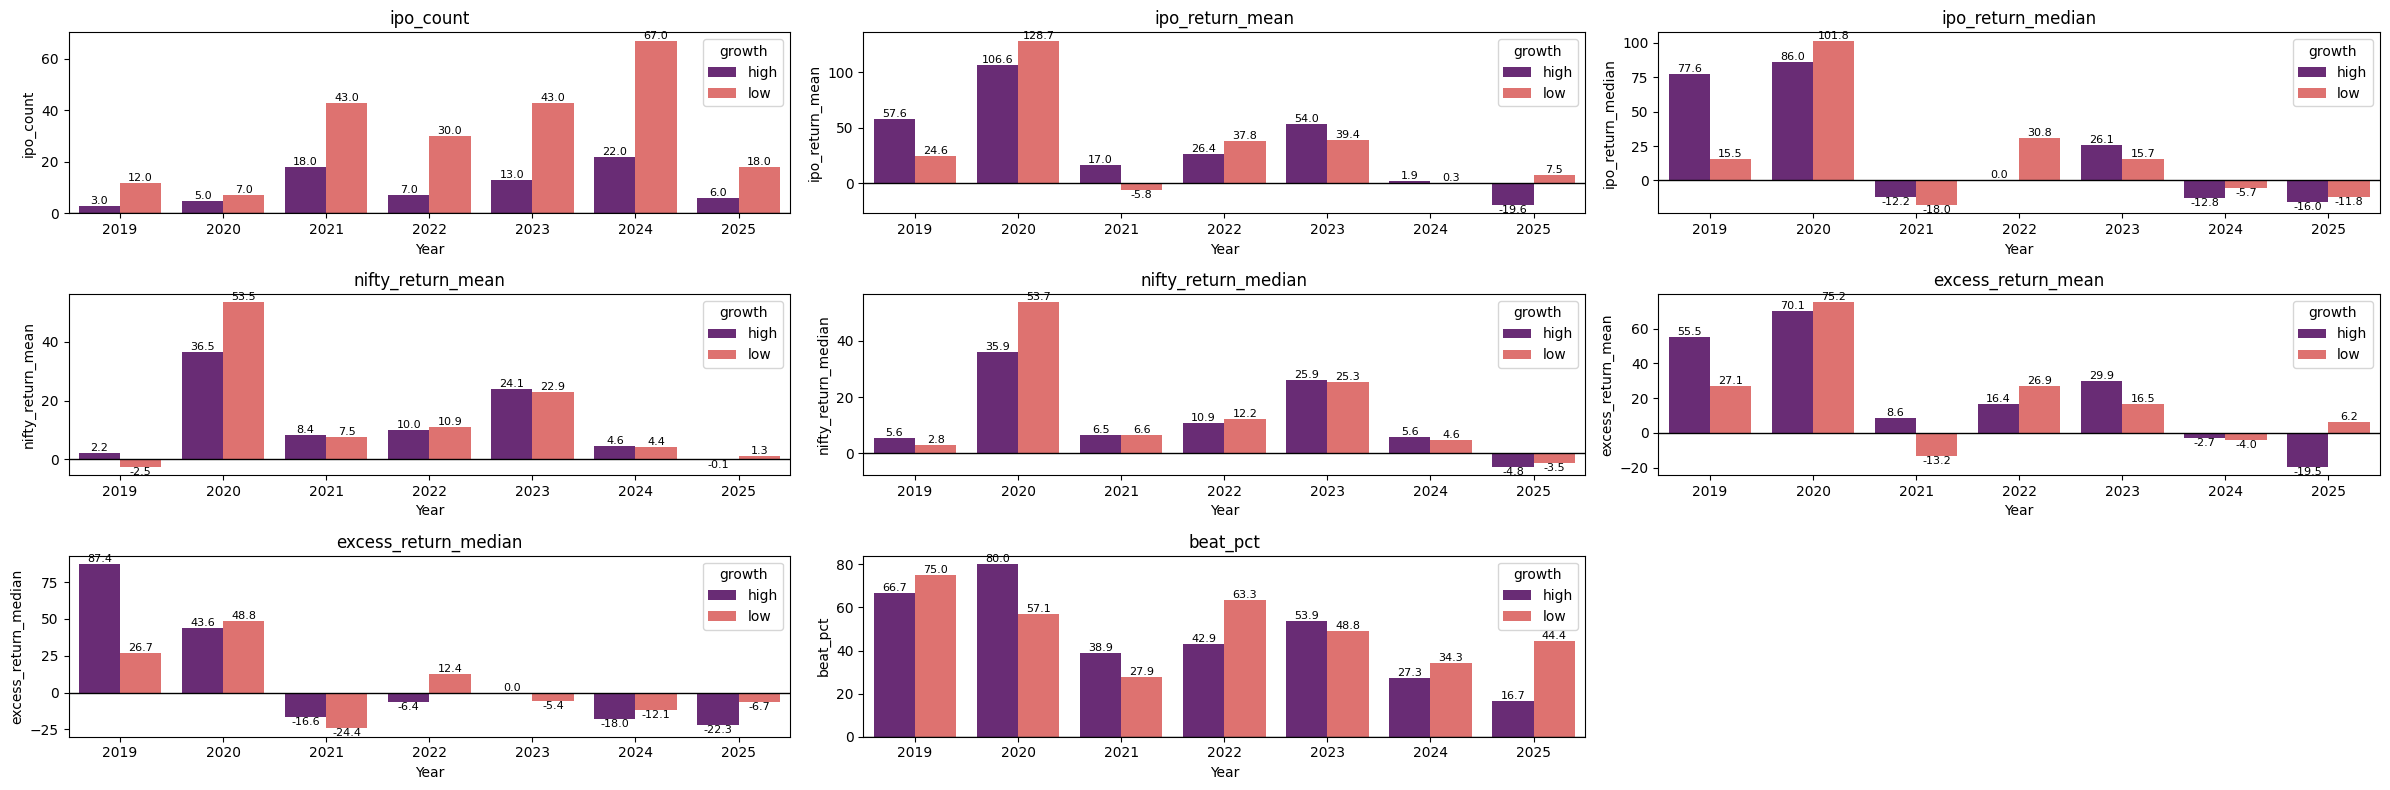

In [ ]:
cols = ['ipo_count', 'ipo_return_mean', 'ipo_return_median',
        'nifty_return_mean', 'nifty_return_median',
        'excess_return_mean', 'excess_return_median', 'beat_pct']

fig, axes = plt.subplots(3, 3, figsize=(24, 8))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.barplot(data=summary_by_year, x='open_date', y=col, hue='growth',
                palette='magma', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Year')
    ax.set_ylabel(col)
    ax.axhline(0, color='black', linewidth=1)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f', fontsize=8)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

2020 is behaving a little differently

In [65]:
filtered = data[data['open_date'].dt.year!= 2020]

Statistical test with whole data

In [66]:
from scipy.stats import mannwhitneyu

high = data[data['growth'] == 'high']['excess_return']
low = data[data['growth'] == 'low']['excess_return']

stat, p = mannwhitneyu(high, low, alternative='two-sided')
if p> 0.05:
    print(f"There is no difference: {round(p,10)}")
else:
    print(f"There is difference: {round(p,10)}")

There is no difference: 0.9351185735


Statistical Test with filtered data

In [68]:
from scipy.stats import mannwhitneyu

high = filtered[filtered['growth'] == 'high']['excess_return']
low = filtered[filtered['growth'] == 'low']['excess_return']

stat, p = mannwhitneyu(high, low, alternative='two-sided')
if p> 0.05:
    print(f"There is no difference: {round(p,10)}")
else:
    print(f"There is difference: {round(p,10)}")

There is no difference: 0.9107397058


` There is no statistical difference in high and low growth classes, IPO with high listing pop does not indicate a higher`

`return in future, compared to Nifty50 stocks`